In [ ]:

print("PlantVillage duplicate detection setup is ready!")


PlantVillage duplicate detection setup is ready!


In [ ]:

from google.colab import files

uploaded = files.upload()

import os
import shutil

# Create Kaggle configuration directory
os.makedirs("/root/.kaggle", exist_ok=True)

# Move the uploaded credentials into the correct location
shutil.move("kaggle.json", "/root/.kaggle/kaggle.json")

# Set secure file permissions
os.chmod("/root/.kaggle/kaggle.json", 0o600)

print("Kaggle configured successfully!")


Saving kaggle.json to kaggle (1).json
Kaggle configured successfully!


In [ ]:

!pip -q install kaggle

!kaggle datasets download -d abdallahalidev/plantvillage-dataset

import zipfile
import os

zip_path = "/content/plantvillage-dataset.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    files_list = z.namelist()

print("Total files and folders:", len(files_list))
print("\nSample paths:")
for path in files_list[:25]:
    print(path)



Dataset URL: https://www.kaggle.com/datasets/abdallahalidev/plantvillage-dataset
License(s): CC-BY-NC-SA-4.0
plantvillage-dataset.zip: Skipping, found more recently modified local copy (use --force to force download)
Total files and folders: 162916

Sample paths:
plantvillage dataset/color/Apple___Apple_scab/00075aa8-d81a-4184-8541-b692b78d398a___FREC_Scab 3335.JPG
plantvillage dataset/color/Apple___Apple_scab/01a66316-0e98-4d3b-a56f-d78752cd043f___FREC_Scab 3003.JPG
plantvillage dataset/color/Apple___Apple_scab/01f3deaa-6143-4b6c-9c22-620a46d8be04___FREC_Scab 3112.JPG
plantvillage dataset/color/Apple___Apple_scab/0208f4eb-45a4-4399-904e-989ac2c6257c___FREC_Scab 3037.JPG
plantvillage dataset/color/Apple___Apple_scab/023123cb-7b69-4c9f-a521-766d7c8543bb___FREC_Scab 3487.JPG
plantvillage dataset/color/Apple___Apple_scab/0261a6e4-21f8-481a-8827-b674e6955644___FREC_Scab 3055.JPG
plantvillage dataset/color/Apple___Apple_scab/029424b0-0ef5-491b-9ef5-069190d24d8f___FREC_Scab 3504.JPG
plantvil

In [ ]:

import zipfile
from collections import Counter
from pathlib import PurePosixPath

ZIP_PATH = "/content/plantvillage-dataset.zip"

TARGET_CROPS = {"Apple", "Corn", "Orange", "Soybean"}
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png"}

crop_counts = Counter()
class_counts = Counter()

with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    for member in archive.infolist():
        if member.is_dir():
            continue

        path = PurePosixPath(member.filename)
        parts = path.parts

        # Expected: dataset/color/Class_Name/image.jpg
        if len(parts) != 4:
            continue

        if parts[0] != "plantvillage dataset" or parts[1] != "color":
            continue

        if path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue

        class_name = parts[2]
        crop_name = class_name.split("___")[0]

        if crop_name not in TARGET_CROPS:
            continue

        crop_counts[crop_name] += 1
        class_counts[class_name] += 1

print("IMAGE COUNTS BY CROP")
for crop in sorted(TARGET_CROPS):
    print(f"{crop}: {crop_counts[crop]:,}")

print("\nIMAGE COUNTS BY DISEASE CLASS")
for name, count in sorted(class_counts.items()):
    print(f"{name}: {count:,}")

print("\nTotal selected images:", sum(crop_counts.values()))
print("Total disease classes:", len(class_counts))
import zipfile
from collections import Counter
from pathlib import PurePosixPath

ZIP_PATH = "/content/plantvillage-dataset.zip"

crop_counts = Counter()

with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    for member in archive.infolist():
        if member.is_dir():
            continue

        path = PurePosixPath(member.filename)

        if (
            len(path.parts) == 4
            and path.parts[0] == "plantvillage dataset"
            and path.parts[1] == "color"
            and path.suffix.lower() in {".jpg", ".jpeg", ".png"}
        ):
            class_name = path.parts[2]
            crop_name = class_name.split("___")[0]
            crop_counts[crop_name] += 1

print("ALL CROP NAMES FOUND:")
for crop, count in sorted(crop_counts.items()):
    print(f"{crop}: {count}")
import zipfile
from collections import Counter
from pathlib import PurePosixPath

ZIP_PATH = "/content/plantvillage-dataset.zip"

TARGET_CROPS = {
    "Apple",
    "Corn_(maize)",
    "Orange",
    "Soybean"
}

crop_counts = Counter()
class_counts = Counter()

with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    for member in archive.infolist():
        if member.is_dir():
            continue

        path = PurePosixPath(member.filename)

        if (
            len(path.parts) == 4
            and path.parts[0] == "plantvillage dataset"
            and path.parts[1] == "color"
            and path.suffix.lower() in {".jpg", ".jpeg", ".png"}
        ):
            class_name = path.parts[2]
            crop_name = class_name.split("___")[0]

            if crop_name in TARGET_CROPS:
                crop_counts[crop_name] += 1
                class_counts[class_name] += 1

print("IMAGE COUNTS BY CROP")
for crop, count in sorted(crop_counts.items()):
    print(f"{crop}: {count:,}")

print("\nIMAGE COUNTS BY DISEASE CLASS")
for class_name, count in sorted(class_counts.items()):
    print(f"{class_name}: {count:,}")

print(f"\nTotal selected images: {sum(crop_counts.values()):,}")
print(f"Total disease classes: {len(class_counts)}")


IMAGE COUNTS BY CROP
Apple: 3,171
Corn: 0
Orange: 5,507
Soybean: 5,090

IMAGE COUNTS BY DISEASE CLASS
Apple___Apple_scab: 630
Apple___Black_rot: 621
Apple___Cedar_apple_rust: 275
Apple___healthy: 1,645
Orange___Haunglongbing_(Citrus_greening): 5,507
Soybean___healthy: 5,090

Total selected images: 13768
Total disease classes: 6
ALL CROP NAMES FOUND:
Apple: 3171
Blueberry: 1502
Cherry_(including_sour): 1906
Corn_(maize): 3852
Grape: 4062
Orange: 5507
Peach: 2657
Pepper,_bell: 2475
Potato: 2152
Raspberry: 371
Soybean: 5090
Squash: 1835
Strawberry: 1565
Tomato: 18160
IMAGE COUNTS BY CROP
Apple: 3,171
Corn_(maize): 3,852
Orange: 5,507
Soybean: 5,090

IMAGE COUNTS BY DISEASE CLASS
Apple___Apple_scab: 630
Apple___Black_rot: 621
Apple___Cedar_apple_rust: 275
Apple___healthy: 1,645
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot: 513
Corn_(maize)___Common_rust_: 1,192
Corn_(maize)___Northern_Leaf_Blight: 985
Corn_(maize)___healthy: 1,162
Orange___Haunglongbing_(Citrus_greening): 5,507
Soybe

In [ ]:

import zipfile
import hashlib
from collections import defaultdict
from pathlib import PurePosixPath

ZIP_PATH = "/content/plantvillage-dataset.zip"

TARGET_CROPS = {
    "Apple",
    "Corn_(maize)",
    "Orange",
    "Soybean"
}

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png"}

# SHA-256 hash -> list of file paths
hash_to_files = defaultdict(list)

with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    selected_members = []

    for member in archive.infolist():
        if member.is_dir():
            continue

        path = PurePosixPath(member.filename)

        if (
            len(path.parts) == 4
            and path.parts[0] == "plantvillage dataset"
            and path.parts[1] == "color"
            and path.suffix.lower() in IMAGE_EXTENSIONS
            and path.parts[2].split("___")[0] in TARGET_CROPS
        ):
            selected_members.append(member)

    print(f"Files to scan: {len(selected_members):,}")

    for i, member in enumerate(selected_members, start=1):
        sha256 = hashlib.sha256()

        with archive.open(member, "r") as file:
            for chunk in iter(lambda: file.read(1024 * 1024), b""):
                sha256.update(chunk)

        hash_to_files[sha256.hexdigest()].append(member.filename)

        if i % 2000 == 0:
            print(f"Processed {i:,}/{len(selected_members):,} images")

# Keep only groups with identical file contents
exact_duplicate_groups = [
    files for files in hash_to_files.values()
    if len(files) > 1
]

duplicate_file_count = sum(
    len(files) for files in exact_duplicate_groups
)
extra_duplicate_count = sum(
    len(files) - 1 for files in exact_duplicate_groups
)

print("\n--- EXACT DUPLICATE RESULTS ---")
print(f"Unique file hashes: {len(hash_to_files):,}")
print(f"Duplicate groups: {len(exact_duplicate_groups):,}")
print(f"Files belonging to duplicate groups: {duplicate_file_count:,}")
print(f"Extra duplicate copies: {extra_duplicate_count:,}")

print("\n--- DUPLICATE GROUP DETAILS ---")
for group_number, files in enumerate(exact_duplicate_groups, start=1):
    print(f"\nGroup {group_number}:")
    for filename in files:
        print(" ", filename)


Files to scan: 17,620
Processed 2,000/17,620 images
Processed 4,000/17,620 images
Processed 6,000/17,620 images
Processed 8,000/17,620 images
Processed 10,000/17,620 images
Processed 12,000/17,620 images
Processed 14,000/17,620 images
Processed 16,000/17,620 images

--- EXACT DUPLICATE RESULTS ---
Unique file hashes: 17,613
Duplicate groups: 7
Files belonging to duplicate groups: 14
Extra duplicate copies: 7

--- DUPLICATE GROUP DETAILS ---

Group 1:
  plantvillage dataset/color/Apple___healthy/11beda66-01e9-4bfd-be37-c0f8646d1478___RS_HL 6271.JPG
  plantvillage dataset/color/Apple___healthy/13298d36-4425-437d-ae8e-c7d70e200084___RS_HL 6271.JPG

Group 2:
  plantvillage dataset/color/Apple___healthy/14896dc0-688d-456f-b5ec-a037695b0193___RS_HL 6268.JPG
  plantvillage dataset/color/Apple___healthy/c21cf428-bfc3-4710-b5d2-69d1c0e94748___RS_HL 6268.JPG

Group 3:
  plantvillage dataset/color/Apple___healthy/1ab5e019-e5f0-4d8e-a252-94cb0aab8b0a___RS_HL 6269.JPG
  plantvillage dataset/color/A

In [ ]:
!pip -q install ImageHash Pillow
import PIL
import imagehash

print("Pillow:", PIL.__version__)
print("ImageHash:", imagehash.__version__)
print("Libraries ready!")

Pillow: 11.3.0
ImageHash: 4.3.2
Libraries ready!


In [ ]:

import zipfile
import io
import pandas as pd
import imagehash
from PIL import Image
from pathlib import PurePosixPath

ZIP_PATH = "/content/plantvillage-dataset.zip"

TARGET_CROPS = {
    "Apple",
    "Corn_(maize)",
    "Orange",
    "Soybean"
}

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png"}

records = []

with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    members = [
        member for member in archive.infolist()
        if (
            not member.is_dir()
            and len(PurePosixPath(member.filename).parts) == 4
            and PurePosixPath(member.filename).parts[0] == "plantvillage dataset"
            and PurePosixPath(member.filename).parts[1] == "color"
            and PurePosixPath(member.filename).suffix.lower() in IMAGE_EXTENSIONS
            and PurePosixPath(member.filename).parts[2].split("___")[0] in TARGET_CROPS
        )
    ]

    print(f"Images to process: {len(members):,}")

    for i, member in enumerate(members, start=1):
        try:
            with archive.open(member) as file:
                image = Image.open(io.BytesIO(file.read())).convert("RGB")
                phash = str(imagehash.phash(image))

            path = PurePosixPath(member.filename)

            records.append({
                "path": member.filename,
                "class": path.parts[2],
                "crop": path.parts[2].split("___")[0],
                "phash": phash
            })

        except Exception as error:
            print(f"Could not process {member.filename}: {error}")

        if i % 2000 == 0:
            print(f"Processed {i:,}/{len(members):,}")

phash_df = pd.DataFrame(records)
phash_df.to_csv("/content/plantvillage_phashes.csv", index=False)

print("\n--- pHash processing complete ---")
print(f"Images successfully processed: {len(phash_df):,}")
print("Saved to /content/plantvillage_phashes.csv")
display(phash_df.head())


Images to process: 17,620
Processed 2,000/17,620
Processed 4,000/17,620
Processed 6,000/17,620
Processed 8,000/17,620
Processed 10,000/17,620
Processed 12,000/17,620
Processed 14,000/17,620
Processed 16,000/17,620

--- pHash processing complete ---
Images successfully processed: 17,620
Saved to /content/plantvillage_phashes.csv


,path,class,crop,phash
0,plantvillage dataset/color/Apple___Apple_scab/...,Apple___Apple_scab,Apple,eeb185d21aca690f
1,plantvillage dataset/color/Apple___Apple_scab/...,Apple___Apple_scab,Apple,b9e184d31a9c1db5
2,plantvillage dataset/color/Apple___Apple_scab/...,Apple___Apple_scab,Apple,96ed92e04b966996
3,plantvillage dataset/color/Apple___Apple_scab/...,Apple___Apple_scab,Apple,fcfc005a4b4d7c46
4,plantvillage dataset/color/Apple___Apple_scab/...,Apple___Apple_scab,Apple,abfd859095925a9a


In [ ]:

!pip -q install pybktree


  Preparing metadata (setup.py) ... done


In [ ]:

import pybktree
import pandas as pd

THRESHOLD = 4

# Convert hexadecimal perceptual hashes to integers
hash_ints = [int(value, 16) for value in phash_df["phash"]]

# Hamming distance between two 64-bit hashes
def hamming_distance(hash1, hash2):
    return (hash1 ^ hash2).bit_count()

# Build the BK-tree
tree = pybktree.BKTree(hamming_distance, hash_ints)

# Find pairs with distance <= threshold
candidate_pairs = set()

for i, hash_value in enumerate(hash_ints):
    matches = tree.find(hash_value, THRESHOLD)

    for distance, matched_hash in matches:
        # Identical hashes and the same image index are not near-duplicate pairs
        if distance == 0:
            continue

        # Hash values can repeat, so include every matching image index.
        # We'll construct the full list of pairs below using a hash-to-indices map.

hash_to_indices = {}
for i, hash_value in enumerate(hash_ints):
    hash_to_indices.setdefault(hash_value, []).append(i)

for i, hash_value in enumerate(hash_ints):
    matches = tree.find(hash_value, THRESHOLD)

    for distance, matched_hash in matches:
        if distance == 0:
            continue

        for j in hash_to_indices[matched_hash]:
            if j > i:
                candidate_pairs.add((i, j, distance))

# Create a results table
off_rows = []

for i, j, distance in sorted(candidate_pairs):
    off_rows.append({
        "image_1": phash_df.iloc[i]["path"],
        "class_1": phash_df.iloc[i]["class"],
        "image_2": phash_df.iloc[j]["path"],
        "class_2": phash_df.iloc[j]["class"],
        "hamming_distance": distance,
        "cross_class": (
            phash_df.iloc[i]["class"] != phash_df.iloc[j]["class"]
        )
    })

near_duplicates_off = pd.DataFrame(off_rows)

near_duplicates_off.to_csv(
    "/content/near_duplicates_rotation_flip_OFF.csv",
    index=False
)

print("--- NEAR-DUPLICATE RESULTS: ROTATION/FLIP OFF ---")
print("Threshold:", THRESHOLD)
print("Candidate pairs:", len(near_duplicates_off))

if len(near_duplicates_off):
    print("Cross-class pairs:", int(near_duplicates_off["cross_class"].sum()))
    print("\nPairs by Hamming distance:")
    print(near_duplicates_off["hamming_distance"].value_counts().sort_index())
    print("\nFirst 20 candidate pairs:")
    display(near_duplicates_off.head(20))
else:
    print("No candidate pairs found at this threshold.")


--- NEAR-DUPLICATE RESULTS: ROTATION/FLIP OFF ---
Threshold: 4
Candidate pairs: 1043
Cross-class pairs: 37

Pairs by Hamming distance:
hamming_distance
2     65
4    978
Name: count, dtype: int64

First 20 candidate pairs:


,image_1,class_1,image_2,class_2,hamming_distance,cross_class
0,plantvillage dataset/color/Apple___Black_rot/3...,Apple___Black_rot,plantvillage dataset/color/Apple___Black_rot/f...,Apple___Black_rot,4,False
1,plantvillage dataset/color/Apple___Black_rot/4...,Apple___Black_rot,plantvillage dataset/color/Apple___Black_rot/f...,Apple___Black_rot,4,False
2,plantvillage dataset/color/Apple___Black_rot/6...,Apple___Black_rot,plantvillage dataset/color/Apple___Black_rot/f...,Apple___Black_rot,4,False
3,plantvillage dataset/color/Apple___healthy/148...,Apple___healthy,plantvillage dataset/color/Soybean___healthy/2...,Soybean___healthy,4,True
4,plantvillage dataset/color/Apple___healthy/149...,Apple___healthy,plantvillage dataset/color/Soybean___healthy/1...,Soybean___healthy,4,True
5,plantvillage dataset/color/Apple___healthy/149...,Apple___healthy,plantvillage dataset/color/Soybean___healthy/2...,Soybean___healthy,4,True
6,plantvillage dataset/color/Apple___healthy/269...,Apple___healthy,plantvillage dataset/color/Soybean___healthy/c...,Soybean___healthy,4,True
7,plantvillage dataset/color/Apple___healthy/298...,Apple___healthy,plantvillage dataset/color/Apple___healthy/9fc...,Apple___healthy,4,False
8,plantvillage dataset/color/Apple___healthy/2ab...,Apple___healthy,plantvillage dataset/color/Soybean___healthy/4...,Soybean___healthy,4,True
9,plantvillage dataset/color/Apple___healthy/375...,Apple___healthy,plantvillage dataset/color/Apple___healthy/abc...,Apple___healthy,4,False


In [ ]:
print("Threshold used:", THRESHOLD)
print("Total near-duplicate candidate pairs:", len(near_duplicates_off))

print(
    "Cross-class candidate pairs:",
    int(near_duplicates_off["cross_class"].sum())
)

print("\nCandidate pairs by Hamming distance:")
print(
    near_duplicates_off["hamming_distance"]
    .value_counts()
    .sort_index()
)

print("\nCross-class pairs by class combination:")
cross = near_duplicates_off[
    near_duplicates_off["cross_class"]
].copy()

cross["class_pair"] = cross.apply(
    lambda row: " | ".join(
        sorted([row["class_1"], row["class_2"]])
    ),
    axis=1
)

print(cross["class_pair"].value_counts())

Threshold used: 4
Total near-duplicate candidate pairs: 1043
Cross-class candidate pairs: 37

Candidate pairs by Hamming distance:
hamming_distance
2     65
4    978
Name: count, dtype: int64

Cross-class pairs by class combination:
class_pair
Orange___Haunglongbing_(Citrus_greening) | Soybean___healthy    21
Apple___healthy | Soybean___healthy                             16
Name: count, dtype: int64


In [ ]:

import pybktree
import pandas as pd

hash_ints = [int(value, 16) for value in phash_df["phash"]]

def hamming_distance(a, b):
    return (a ^ b).bit_count()

tree = pybktree.BKTree(hamming_distance, hash_ints)

hash_to_indices = {}
for i, h in enumerate(hash_ints):
    hash_to_indices.setdefault(h, []).append(i)

# Search up to distance 6 once; use the results for both thresholds
all_pairs = set()

for i, h in enumerate(hash_ints):
    for distance, matched_hash in tree.find(h, 6):
        if distance == 0:
            continue
        for j in hash_to_indices[matched_hash]:
            if j > i:
                all_pairs.add((i, j, distance))

def make_results(max_distance):
    rows = []
    for i, j, distance in all_pairs:
        if distance <= max_distance:
            rows.append({
                "image_1": phash_df.iloc[i]["path"],
                "class_1": phash_df.iloc[i]["class"],
                "image_2": phash_df.iloc[j]["path"],
                "class_2": phash_df.iloc[j]["class"],
                "hamming_distance": distance,
                "cross_class": (
                    phash_df.iloc[i]["class"]
                    != phash_df.iloc[j]["class"]
                )
            })
    return pd.DataFrame(rows)

results_4 = make_results(4)
results_6 = make_results(6)

comparison = pd.DataFrame([
    {
        "threshold": 4,
        "candidate_pairs": len(results_4),
        "cross_class_pairs": int(results_4["cross_class"].sum())
    },
    {
        "threshold": 6,
        "candidate_pairs": len(results_6),
        "cross_class_pairs": int(results_6["cross_class"].sum())
    }
])

results_4.to_csv("/content/near_duplicates_OFF_threshold4.csv", index=False)
results_6.to_csv("/content/near_duplicates_OFF_threshold6.csv", index=False)

print("ROTATION/FLIP OFF — THRESHOLD COMPARISON")
display(comparison)


ROTATION/FLIP OFF — THRESHOLD COMPARISON


,threshold,candidate_pairs,cross_class_pairs
0,4,1043,37
1,6,6783,464


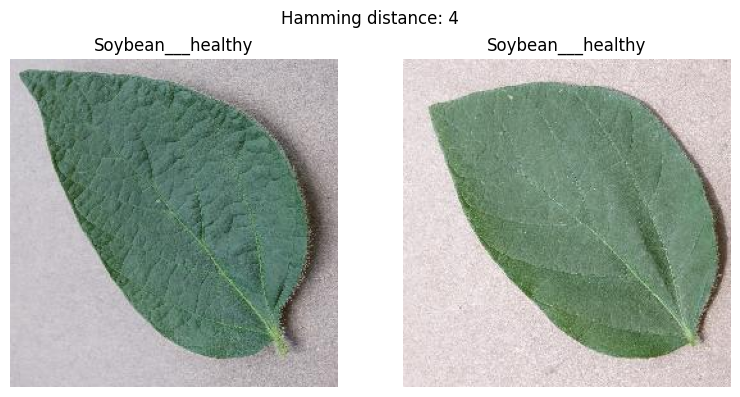

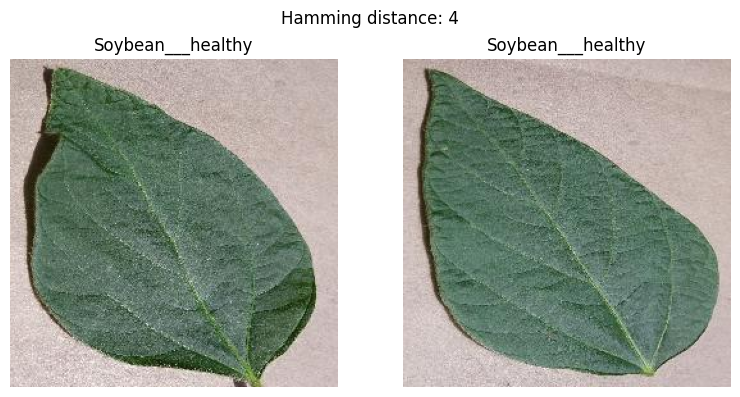

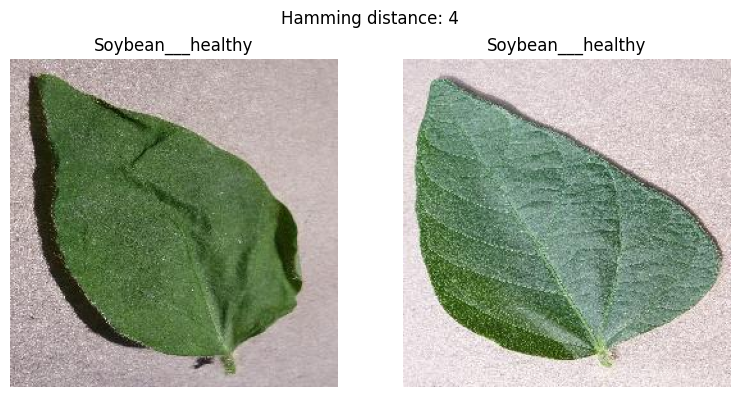

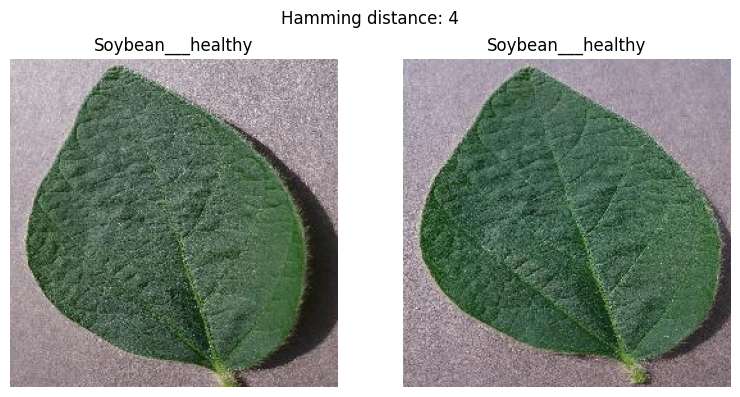

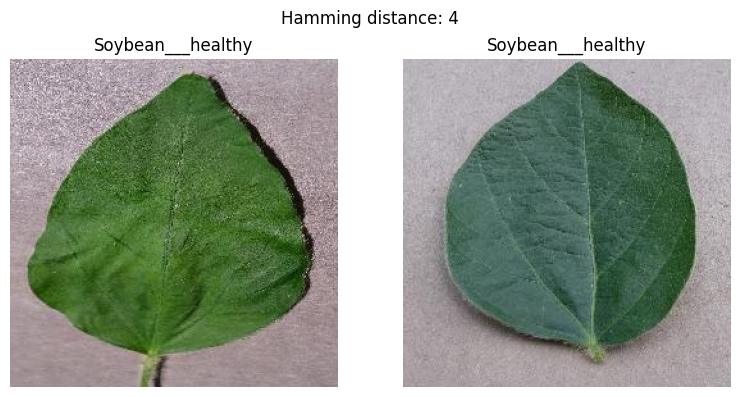

...

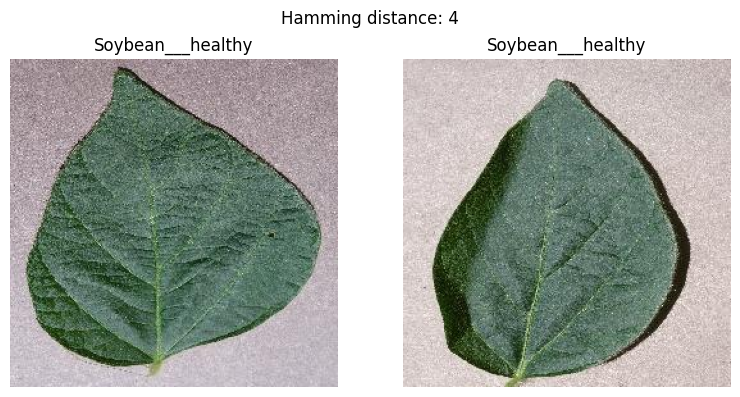

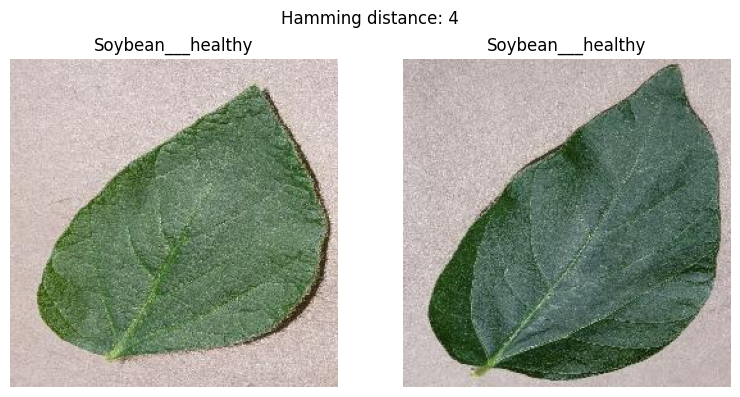

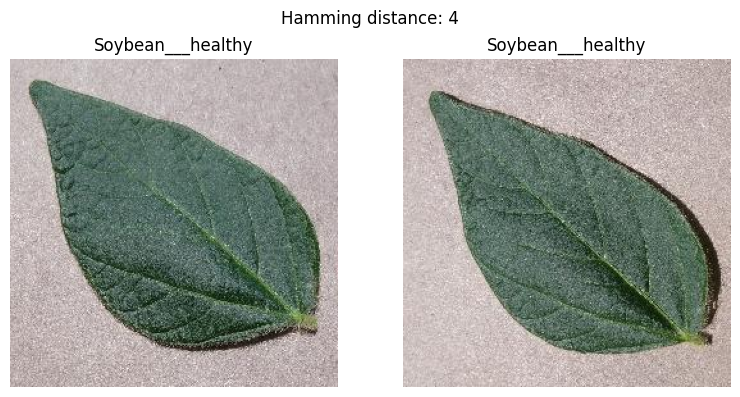

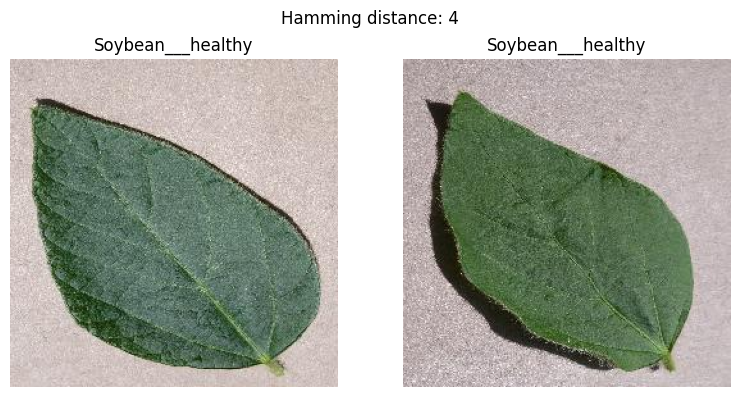

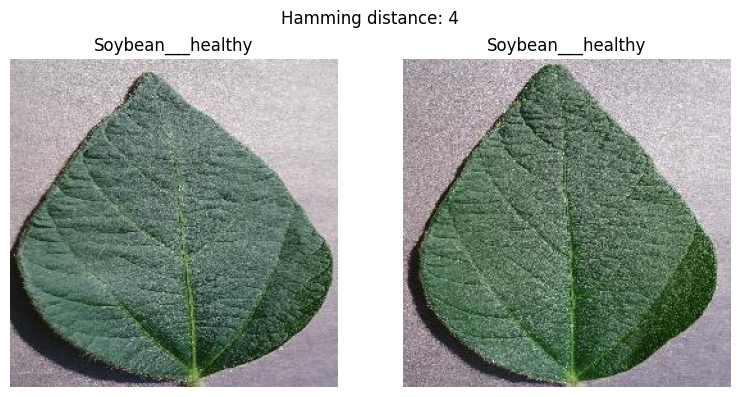

In [ ]:
import zipfile
import io
import matplotlib.pyplot as plt
from PIL import Image
import random

ZIP_PATH = "/content/plantvillage-dataset.zip"

# Sample up to 20 candidate pairs
sample_pairs = results_4.sample(
    n=min(20, len(results_4)),
    random_state=42
)

with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    for _, row in sample_pairs.iterrows():
        path1 = row["image_1"]
        path2 = row["image_2"]

        img1 = Image.open(
            io.BytesIO(archive.read(path1))
        ).convert("RGB")
        img2 = Image.open(
            io.BytesIO(archive.read(path2))
        ).convert("RGB")

        fig, axes = plt.subplots(1, 2, figsize=(8, 4))

        axes[0].imshow(img1)
        axes[0].set_title(str(row["class_1"])[:35])
        axes[0].axis("off")

        axes[1].imshow(img2)
        axes[1].set_title(str(row["class_2"])[:35])
        axes[1].axis("off")

        fig.suptitle(
            f"Hamming distance: {row['hamming_distance']}"
        )
        plt.tight_layout()
        plt.show()



In [ ]:
import pandas as pd

review_df = results_4.copy()

review_df["review_decision"] = "pending"
review_df["remove_image"] = ""
review_df["review_notes"] = ""

review_df.to_csv(
    "/content/plantvillage_threshold4_review.csv",
    index=False
)

print("Review CSV saved!")
print("Candidate pairs:", len(review_df))
print("/content/plantvillage_threshold4_review.csv")

Review CSV saved!
Candidate pairs: 1043
/content/plantvillage_threshold4_review.csv


In [ ]:
import zipfile
import hashlib
import pandas as pd

ZIP_PATH = "/content/plantvillage-dataset.zip"

# Use the same 17,620 selected images from your analysis
source_df = phash_df[["path", "class", "phash"]].copy()

seen_hashes = {}
clean_rows = []
removed_rows = []

with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    for _, row in source_df.iterrows():
        path = row["path"]
        image_bytes = archive.read(path)
        sha256 = hashlib.sha256(image_bytes).hexdigest()

        if sha256 in seen_hashes:
            removed_rows.append({
                "removed_image": path,
                "kept_image": seen_hashes[sha256],
                "class": row["class"],
                "sha256": sha256,
                "reason": "Exact duplicate (SHA-256)"
            })
        else:
            seen_hashes[sha256] = path
            clean_rows.append({
                "image_path": path,
                "class": row["class"],
                "sha256": sha256,
                "phash": row["phash"]
            })

clean_df = pd.DataFrame(clean_rows)
removed_df = pd.DataFrame(
    removed_rows,
    columns=[
        "removed_image", "kept_image",
        "class", "sha256", "reason"
    ]
)

clean_df.to_csv(
    "/content/plantvillage_color_cleaned.csv",
    index=False
)
removed_df.to_csv(
    "/content/plantvillage_exact_duplicates_removed.csv",
    index=False
)

print("Original images:", len(source_df))
print("Images in cleaned CSV:", len(clean_df))
print("Exact duplicate copies removed:", len(removed_df))
print("\nFiles created:")
print("/content/plantvillage_color_cleaned.csv")
print("/content/plantvillage_exact_duplicates_removed.csv")

from google.colab import files
files.download("/content/plantvillage_color_cleaned.csv")

Original images: 17620
Images in cleaned CSV: 17613
Exact duplicate copies removed: 7

Files created:
/content/plantvillage_color_cleaned.csv
/content/plantvillage_exact_duplicates_removed.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>